# E-Commerce Sales & Customer Analytics

## Project Overview

This project analyzes e-commerce sales data from 2017 to 2019 using Python.

The objective is to understand sales performance, customer behavior, product performance,
profitability, location-wise sales and salesperson performance.

### Tools & Technologies
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn

### Key Areas of Analysis
- Data Cleaning
- Data Transformation
- Exploratory Data Analysis
- Sales Analysis
- Customer Analysis
- Product Analysis
- Location Analysis
- Profit Analysis
- Data Visualization

In [1]:
# E-Commerce Sales & Customer Analytics
# Python Project
import pandas as pd    #working with tables and datasets                                 #import all essential packages
import numpy as np     #numerical calculations and array
import matplotlib.pyplot as plt #for creating graphs and charts
import seaborn as sns      #better looking statistical viswalistions
#Now load the three sales sheets:

sales_2017=pd.read_excel("/content/Demo_file.xlsx",sheet_name="2017 Sales")
sales_2018=pd.read_excel("/content/Demo_file.xlsx",sheet_name="2018 Sales")
sales_2019=pd.read_excel("/content/Demo_file.xlsx",sheet_name="2019 Sales")

#check whether it works

print(sales_2017.shape)
print(sales_2018.shape)
print(sales_2019.shape)


(4980, 8)
(4909, 8)
(1000, 8)


In [2]:
#now combine all data sheets into one dataframe
sales=pd.concat([sales_2017,sales_2018,sales_2019],ignore_index=True)
sales.shape
sales.head()

,Order ID,Product ID,Location ID,Sales Person ID,Customer ID,Purchase Date,Quantity,Price
0,OID10001,PID2071,A152,EMP1009,C1499,2017-09-23,1,136
1,OID10002,PID2053,A139,EMP1007,C1359,2017-02-07,1,596
2,OID10005,PID2030,A121,EMP1003,C1220,2017-06-27,1,1899
3,OID10007,PID2001,A122,EMP1003,C1368,2017-01-12,4,951
4,OID10009,PID2082,A101,EMP1029,C1764,2017-07-28,1,1103


##data cleaning and preperation

In [3]:
print("Missing values:")
print(sales.isnull().sum())

print("\nDuplicate rows:")
print(sales.duplicated().sum())

print("\nData types:")
print(sales.dtypes)

Missing values:
Order ID           0
Product ID         0
Location ID        0
Sales Person ID    0
Customer ID        0
Purchase Date      0
Quantity           0
Price              0
dtype: int64

Duplicate rows:
0

Data types:
Order ID                   object
Product ID                 object
Location ID                object
Sales Person ID            object
Customer ID                object
Purchase Date      datetime64[ns]
Quantity                    int64
Price                       int64
dtype: object


## Feature Engineering

In [98]:
sales_analysis["Revenue"] = (
    sales_analysis["Quantity"] *
    sales_analysis["Price"]
)

sales_analysis["Profit"] = (
    sales_analysis["Revenue"] -
    (sales_analysis["Cost"] * sales_analysis["Quantity"])
)

sales_analysis["Profit Margin %"] = (
    sales_analysis["Profit"] /
    sales_analysis["Revenue"] * 100
)

sales_analysis["Year"] = (
    sales_analysis["Purchase Date"].dt.year
)

sales_analysis["Month"] = (
    sales_analysis["Purchase Date"].dt.month
)

sales_analysis["Month Name"] = (
    sales_analysis["Purchase Date"].dt.month_name()
)

In [4]:
sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10889 entries, 0 to 10888
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Order ID         10889 non-null  object        
 1   Product ID       10889 non-null  object        
 2   Location ID      10889 non-null  object        
 3   Sales Person ID  10889 non-null  object        
 4   Customer ID      10889 non-null  object        
 5   Purchase Date    10889 non-null  datetime64[ns]
 6   Quantity         10889 non-null  int64         
 7   Price            10889 non-null  int64         
dtypes: datetime64[ns](1), int64(2), object(5)
memory usage: 680.7+ KB


In [5]:
sales.dtypes #to check the datatype

,0
Order ID,object
Product ID,object
Location ID,object
Sales Person ID,object
Customer ID,object
Purchase Date,datetime64[ns]
Quantity,int64
Price,int64


In [6]:
sales.isnull().sum() #get the no of null values

,0
Order ID,0
Product ID,0
Location ID,0
Sales Person ID,0
Customer ID,0
Purchase Date,0
Quantity,0
Price,0


In [7]:
sales.duplicated().sum() #to find whether any duplicate rows are there

np.int64(0)

In [8]:
sales.describe()   #return min ,max,avg etc of the value columns

,Purchase Date,Quantity,Price
count,10889,10889.000000,10889.000000
mean,2018-02-05 03:58:26.107080448,1.935715,1217.282671
min,2017-01-01 00:00:00,1.000000,35.000000
25%,2017-07-18 00:00:00,1.000000,561.000000
50%,2018-02-05 00:00:00,1.000000,1278.000000
75%,2018-08-27 00:00:00,3.000000,1798.000000
max,2019-03-15 00:00:00,4.000000,2497.000000
std,NaN,1.084042,706.324170


In [9]:
excelfile=pd.ExcelFile("/content/Demo_file.xlsx")        #kept excel file in "excelfile" and displayed the sheets
excelfile.sheet_names

['2019 Sales',
 '2018 Sales',
 '2017 Sales',
 'Products',
 'Locations',
 'Customers',
 'Sales People',
 'Budgeting',
 'Date Ranges',
 'Sheet1']

In [10]:
products=pd.read_excel("/content/Demo_file.xlsx",sheet_name="Products")    #get products sheet details
products.head()

,Product ID,Product Name,Cost,Original Sale Price,Discount,Current Price,Taxes
0,PID2000,Product 1,1367,2241,0,2241,336.15
1,PID2001,Product 2,504,951,0,951,142.65
2,PID2002,Product 3,534,847,0,847,127.05
3,PID2003,Product 4,1516,1783,0,1783,267.45
4,PID2004,Product 5,665,1278,0,1278,191.70


In [11]:
products.shape


(101, 7)

In [12]:
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101 entries, 0 to 100
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Product ID           101 non-null    object 
 1   Product Name         101 non-null    object 
 2   Cost                 101 non-null    int64  
 3   Original Sale Price  101 non-null    int64  
 4   Discount             101 non-null    int64  
 5   Current Price        101 non-null    int64  
 6   Taxes                101 non-null    float64
dtypes: float64(1), int64(4), object(2)
memory usage: 5.7+ KB


In [13]:
locations = pd.read_excel(             #get location details
    "Demo_file.xlsx",
    sheet_name="Locations"
)

In [14]:
locations.head()

,Location ID,Name,County,State Code,State,Type,Latitude,Longitude,Area Code,Population,Households,Median Income,Land Area,Water Area,Time Zone
0,A100,Anaheim,Orange County,CA,California,City,33.83529,-117.91450,657,350742,99670,60752,129438076,2457142,America/Los Angeles
1,A101,Antioch,Contra Costa County,CA,California,City,38.00492,-121.80579,925,110542,33718,64329,76173197,1842711,America/Los Angeles
2,A102,Bakersfield,Kern County,CA,California,City,35.37329,-119.01871,661,373640,112439,57095,385366784,3809676,America/Los Angeles
3,A103,Berkeley,Alameda County,CA,California,City,37.87159,-122.27275,510,120972,45917,66237,27106077,18715614,America/Los Angeles
4,A104,Burbank,Los Angeles County,CA,California,City,34.18084,-118.30897,818,105319,41361,66076,44947219,94286,America/Los Angeles


In [15]:
locations.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74 entries, 0 to 73
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Location ID    74 non-null     object 
 1   Name           74 non-null     object 
 2   County         74 non-null     object 
 3   State Code     74 non-null     object 
 4   State          74 non-null     object 
 5   Type           74 non-null     object 
 6   Latitude       74 non-null     float64
 7   Longitude      74 non-null     float64
 8   Area Code      74 non-null     int64  
 9   Population     74 non-null     int64  
 10  Households     74 non-null     int64  
 11  Median Income  74 non-null     int64  
 12  Land Area      74 non-null     int64  
 13  Water Area     74 non-null     int64  
 14  Time Zone      74 non-null     object 
dtypes: float64(2), int64(6), object(7)
memory usage: 8.8+ KB


In [16]:
locations.shape

(74, 15)

In [17]:
customers=pd.read_excel("/content/Demo_file.xlsx",sheet_name="Customers")      #get customer data
sales_people=pd.read_excel("/content/Demo_file.xlsx",sheet_name="Sales People") #get sales people data
customers.shape

(801, 2)

In [18]:
sales_people.shape

(45, 2)

In [19]:
customers.head()

,Customer ID,Customer Name
0,C1000,Thomas Duncan
1,C1001,Kenneth Ross
2,C1002,Henry Reyes
3,C1003,Benjamin Carter
4,C1004,Jeremy Schmidt


In [20]:
sales_people.head()

,Salesperson ID,Salesperson Name
0,EMP1000,Fred Robertson
1,EMP1001,Kevin Butler
2,EMP1002,Andrew Bowman
3,EMP1003,Christopher Tucker
4,EMP1004,Kenneth Bradley


In [21]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 801 entries, 0 to 800
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Customer ID    801 non-null    object
 1   Customer Name  801 non-null    object
dtypes: object(2)
memory usage: 12.6+ KB


In [22]:
sales_people.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45 entries, 0 to 44
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Salesperson ID    45 non-null     object
 1   Salesperson Name  45 non-null     object
dtypes: object(2)
memory usage: 852.0+ bytes


In [23]:
#merge the customer,location,sales_people data with the sales table
sales_analysis=sales.copy()
sales_analysis=sales_analysis.merge(products,on="Product ID",how="left")
sales_analysis.head()

,Order ID,Product ID,Location ID,Sales Person ID,Customer ID,Purchase Date,Quantity,Price,Product Name,Cost,Original Sale Price,Discount,Current Price,Taxes
0,OID10001,PID2071,A152,EMP1009,C1499,2017-09-23,1,136,Product 72,72,136,0,136,20.40
1,OID10002,PID2053,A139,EMP1007,C1359,2017-02-07,1,596,Product 54,358,596,0,596,89.40
2,OID10005,PID2030,A121,EMP1003,C1220,2017-06-27,1,1899,Product 31,1044,1899,0,1899,284.85
3,OID10007,PID2001,A122,EMP1003,C1368,2017-01-12,4,951,Product 2,504,951,0,951,142.65
4,OID10009,PID2082,A101,EMP1029,C1764,2017-07-28,1,1103,Product 83,838,1103,0,1103,165.45


In [24]:
sales_analysis.shape

(10889, 14)

In [25]:
sales_analysis["Product Name"].isnull().sum()  #thus every matching pair is merged

np.int64(0)

In [26]:
sales_analysis.columns

Index(['Order ID', 'Product ID', 'Location ID', 'Sales Person ID',
       'Customer ID', 'Purchase Date', 'Quantity', 'Price', 'Product Name',
       'Cost', 'Original Sale Price', 'Discount', 'Current Price', 'Taxes'],
      dtype='object')

In [27]:
sales_analysis["revenue"]=(sales_analysis["Quantity"]*sales_analysis["Price"]) #finding revenue
sales_analysis[["Quantity","Price","revenue"]].head()

,Quantity,Price,revenue
0,1,136,136
1,1,596,596
2,1,1899,1899
3,4,951,3804
4,1,1103,1103


In [28]:
sales_analysis["profit"]=(sales_analysis["revenue"]-(sales_analysis["Cost"]*sales_analysis["Quantity"]))
sales_analysis[["revenue","Cost","Quantity","profit"]].head()

,revenue,Cost,Quantity,profit
0,136,72,1,64
1,596,358,1,238
2,1899,1044,1,855
3,3804,504,4,1788
4,1103,838,1,265


In [29]:
sales_analysis.head()

,Order ID,Product ID,Location ID,Sales Person ID,Customer ID,Purchase Date,Quantity,Price,Product Name,Cost,Original Sale Price,Discount,Current Price,Taxes,revenue,profit
0,OID10001,PID2071,A152,EMP1009,C1499,2017-09-23,1,136,Product 72,72,136,0,136,20.40,136,64
1,OID10002,PID2053,A139,EMP1007,C1359,2017-02-07,1,596,Product 54,358,596,0,596,89.40,596,238
2,OID10005,PID2030,A121,EMP1003,C1220,2017-06-27,1,1899,Product 31,1044,1899,0,1899,284.85,1899,855
3,OID10007,PID2001,A122,EMP1003,C1368,2017-01-12,4,951,Product 2,504,951,0,951,142.65,3804,1788
4,OID10009,PID2082,A101,EMP1029,C1764,2017-07-28,1,1103,Product 83,838,1103,0,1103,165.45,1103,265


In [30]:
sales_analysis["Profit Margin %"] = (
    sales_analysis["profit"] /
    sales_analysis["revenue"] * 100
)
sales_analysis[["Product Name","profit","revenue","Profit Margin %"]].head()



,Product Name,profit,revenue,Profit Margin %
0,Product 72,64,136,47.058824
1,Product 54,238,596,39.932886
2,Product 31,855,1899,45.023697
3,Product 2,1788,3804,47.003155
4,Product 83,265,1103,24.025385


In [31]:
print(sales_analysis["profit"].sum())      #found the major project results
print(sales_analysis['Quantity'].sum())
print(sales_analysis["revenue"].sum())

8343893
21078
25661209


In [32]:
#overall profit margin
total_profit=sales_analysis["profit"].sum()
total_revenue=sales_analysis["revenue"].sum()
profit_margin=(total_profit/total_revenue)*100
print("total_profit:",total_profit)
print("total revenue:",total_revenue)
print("profit margin:",profit_margin,"%")

total_profit: 8343893
total revenue: 25661209
profit margin: 32.5155880223726 %


In [33]:
sales_analysis=sales_analysis.merge(                       #merge customers to sales analysis
    customers,
    on="Customer ID",
    how="left"
)
sales_analysis.head()

,Order ID,Product ID,Location ID,Sales Person ID,Customer ID,Purchase Date,Quantity,Price,Product Name,Cost,Original Sale Price,Discount,Current Price,Taxes,revenue,profit,Profit Margin %,Customer Name
0,OID10001,PID2071,A152,EMP1009,C1499,2017-09-23,1,136,Product 72,72,136,0,136,20.40,136,64,47.058824,Stephen Greene
1,OID10002,PID2053,A139,EMP1007,C1359,2017-02-07,1,596,Product 54,358,596,0,596,89.40,596,238,39.932886,Antonio Shaw
2,OID10005,PID2030,A121,EMP1003,C1220,2017-06-27,1,1899,Product 31,1044,1899,0,1899,284.85,1899,855,45.023697,Eric Bradley
3,OID10007,PID2001,A122,EMP1003,C1368,2017-01-12,4,951,Product 2,504,951,0,951,142.65,3804,1788,47.003155,Jerry Andrews
4,OID10009,PID2082,A101,EMP1029,C1764,2017-07-28,1,1103,Product 83,838,1103,0,1103,165.45,1103,265,24.025385,Charles Perry


In [34]:
sales_analysis['Customer ID'].isnull().sum()

np.int64(0)

In [35]:
#merge location to sales analysis
locations.columns

Index(['Location ID', 'Name', 'County', 'State Code', 'State', 'Type',
       'Latitude', 'Longitude', 'Area Code', 'Population', 'Households',
       'Median Income', 'Land Area', 'Water Area', 'Time Zone'],
      dtype='object')

In [36]:
sales_analysis=sales_analysis.merge(
    locations,
    on="Location ID",
    how="left"
)

In [37]:
sales_analysis.shape

(10889, 32)

In [38]:
sales_analysis["Location ID"].isnull().sum()

np.int64(0)

In [39]:
sales_people.columns

Index(['Salesperson ID', 'Salesperson Name'], dtype='object')

In [40]:
sales_analysis = sales_analysis.merge(
    sales_people,
    left_on="Sales Person ID",
    right_on="Salesperson ID",
    how="left"
)

In [41]:
print(sales_analysis.columns)
print(sales_people.columns)

Index(['Order ID', 'Product ID', 'Location ID', 'Sales Person ID',
       'Customer ID', 'Purchase Date', 'Quantity', 'Price', 'Product Name',
       'Cost', 'Original Sale Price', 'Discount', 'Current Price', 'Taxes',
       'revenue', 'profit', 'Profit Margin %', 'Customer Name', 'Name',
       'County', 'State Code', 'State', 'Type', 'Latitude', 'Longitude',
       'Area Code', 'Population', 'Households', 'Median Income', 'Land Area',
       'Water Area', 'Time Zone', 'Salesperson ID', 'Salesperson Name'],
      dtype='object')
Index(['Salesperson ID', 'Salesperson Name'], dtype='object')


In [42]:

sales_analysis.columns = sales_analysis.columns.str.strip()
sales_people.columns = sales_people.columns.str.strip()

In [43]:
print(sales_analysis.columns.tolist())
print(sales_people.columns.tolist())

['Order ID', 'Product ID', 'Location ID', 'Sales Person ID', 'Customer ID', 'Purchase Date', 'Quantity', 'Price', 'Product Name', 'Cost', 'Original Sale Price', 'Discount', 'Current Price', 'Taxes', 'revenue', 'profit', 'Profit Margin %', 'Customer Name', 'Name', 'County', 'State Code', 'State', 'Type', 'Latitude', 'Longitude', 'Area Code', 'Population', 'Households', 'Median Income', 'Land Area', 'Water Area', 'Time Zone', 'Salesperson ID', 'Salesperson Name']
['Salesperson ID', 'Salesperson Name']


In [44]:
sales_analysis.shape

(10889, 34)

In [45]:
sales_analysis.head()

,Order ID,Product ID,Location ID,Sales Person ID,Customer ID,Purchase Date,Quantity,Price,Product Name,Cost,...,Longitude,Area Code,Population,Households,Median Income,Land Area,Water Area,Time Zone,Salesperson ID,Salesperson Name
0,OID10001,PID2071,A152,EMP1009,C1499,2017-09-23,1,136,Product 72,72,...,-117.28977,909,216108,57580,37047,159326695,1126214,America/Los Angeles,EMP1009,Kenneth Fields
1,OID10002,PID2053,A139,EMP1007,C1359,2017-02-07,1,596,Product 54,358,...,-117.65089,909,171214,47375,54114,129329742,159101,America/Los Angeles,EMP1007,Jeremy Mendoza
2,OID10005,PID2030,A121,EMP1003,C1220,2017-06-27,1,1899,Product 31,1044,...,-119.77237,559,520052,161914,41531,296267437,732167,America/Los Angeles,EMP1003,Christopher Tucker
3,OID10007,PID2001,A122,EMP1003,C1368,2017-01-12,4,951,Product 2,504,...,-117.92534,657,140847,45031,65974,58100816,28063,America/Los Angeles,EMP1003,Christopher Tucker
4,OID10009,PID2082,A101,EMP1029,C1764,2017-07-28,1,1103,Product 83,838,...,-121.80579,925,110542,33718,64329,76173197,1842711,America/Los Angeles,EMP1029,Howard Gardner


In [46]:
#create year and month columns
sales_analysis["year"]=sales_analysis["Purchase Date"].dt.year
sales_analysis["month"]=sales_analysis["Purchase Date"].dt.month

sales_analysis["month_name"]=sales_analysis["Purchase Date"].dt.month_name()



In [47]:
sales_analysis[
    ["Purchase Date", "year", "month", "month_name"]
].head()

,Purchase Date,year,month,month_name
0,2017-09-23,2017,9,September
1,2017-02-07,2017,2,February
2,2017-06-27,2017,6,June
3,2017-01-12,2017,1,January
4,2017-07-28,2017,7,July


In [48]:
yearly_sales=sales_analysis.groupby("year")["revenue"].sum()    #which year generated most revenue
print(yearly_sales)

year
2017    11690763
2018    11565545
2019     2404901
Name: revenue, dtype: int64


In [49]:
yearly_sales=yearly_sales.reset_index()
print(yearly_sales)


   year   revenue
0  2017  11690763
1  2018  11565545
2  2019   2404901


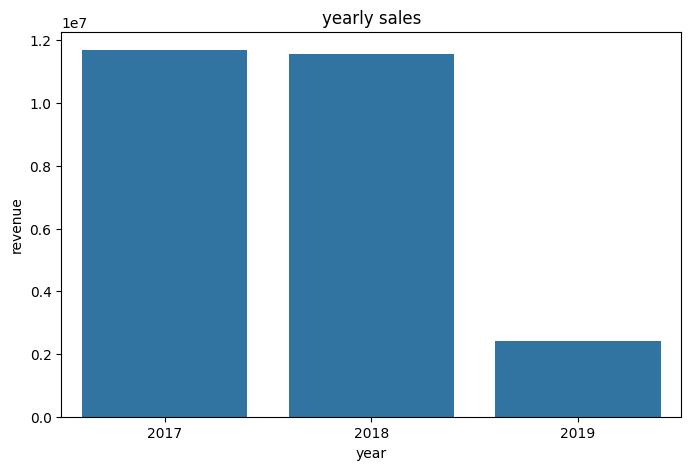

In [50]:
#first project chart
plt.figure(figsize=(8,5))
sns.barplot(
    data=yearly_sales,
    x="year",
    y="revenue"

)
plt.title("yearly sales")
plt.xlabel("year")
plt.ylabel("revenue")
plt.show()

In [51]:
monthly_sales=sales_analysis.groupby(["year","month"])["revenue"].sum().reset_index()          #monthly sales trend
print(monthly_sales)

    year  month  revenue
0   2017      1  1024700
1   2017      2   989964
2   2017      3   916515
3   2017      4   954294
4   2017      5  1011295
5   2017      6  1049952
6   2017      7   893324
7   2017      8   922649
8   2017      9   993425
9   2017     10   916901
10  2017     11  1019213
11  2017     12   998531
12  2018      1   944532
13  2018      2   913174
14  2018      3   983950
15  2018      4   984774
16  2018      5   865939
17  2018      6  1017053
18  2018      7   938285
19  2018      8   887709
20  2018      9   959872
21  2018     10   981802
22  2018     11  1035024
23  2018     12  1053431
24  2019      1   899923
25  2019      2   976706
26  2019      3   528272


In [52]:
monthly_sales.head()

,year,month,revenue
0,2017,1,1024700
1,2017,2,989964
2,2017,3,916515
3,2017,4,954294
4,2017,5,1011295


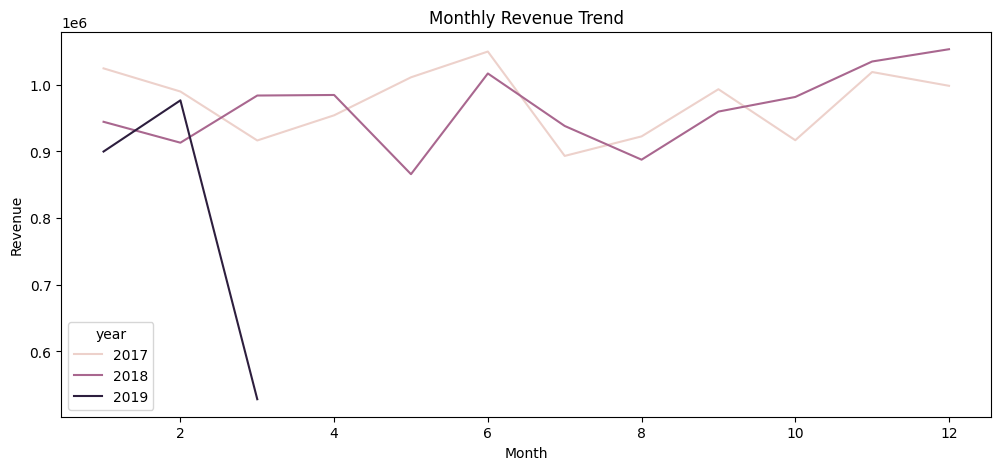

In [53]:
plt.figure(figsize=(12,5))                 #line chart
sns.lineplot(
    data=monthly_sales,
    x="month",
    y="revenue",
    hue="year",
    markers="o"

)
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.show()

In [54]:
#top 10 products by revenue
top_products=sales_analysis.groupby("Product Name")["revenue"].sum().sort_values(ascending=False).head(10)
print(top_products)

Product Name
Product 63    628320
Product 28    604274
Product 47    556710
Product 29    534222
Product 84    528827
Product 59    523624
Product 56    484030
Product 66    474408
Product 33    468146
Product 81    465894
Name: revenue, dtype: int64


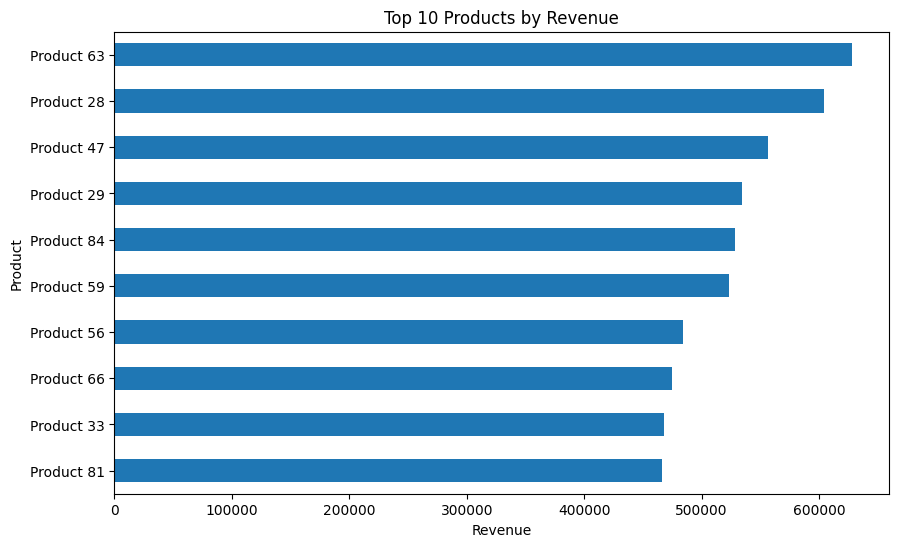

In [55]:
#create chart
plt.figure(figsize=(10,6))

top_products.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")

plt.show()

In [56]:
sales_analysis.columns

Index(['Order ID', 'Product ID', 'Location ID', 'Sales Person ID',
       'Customer ID', 'Purchase Date', 'Quantity', 'Price', 'Product Name',
       'Cost', 'Original Sale Price', 'Discount', 'Current Price', 'Taxes',
       'revenue', 'profit', 'Profit Margin %', 'Customer Name', 'Name',
       'County', 'State Code', 'State', 'Type', 'Latitude', 'Longitude',
       'Area Code', 'Population', 'Households', 'Median Income', 'Land Area',
       'Water Area', 'Time Zone', 'Salesperson ID', 'Salesperson Name', 'year',
       'month', 'month_name'],
      dtype='object')

In [57]:
#top 10 customers by revenue
top_customers = (
    sales_analysis
    .groupby("Customer Name")["revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_customers

,revenue
Customer Name,
Jesse Hill,171261
Thomas Gonzales,159876
Fred Russell,154998
Philip Bailey,136175
Keith Stephens,133183
Aaron Miller,132550
William Medina,131349
David Mendoza,128460
James Armstrong,126377


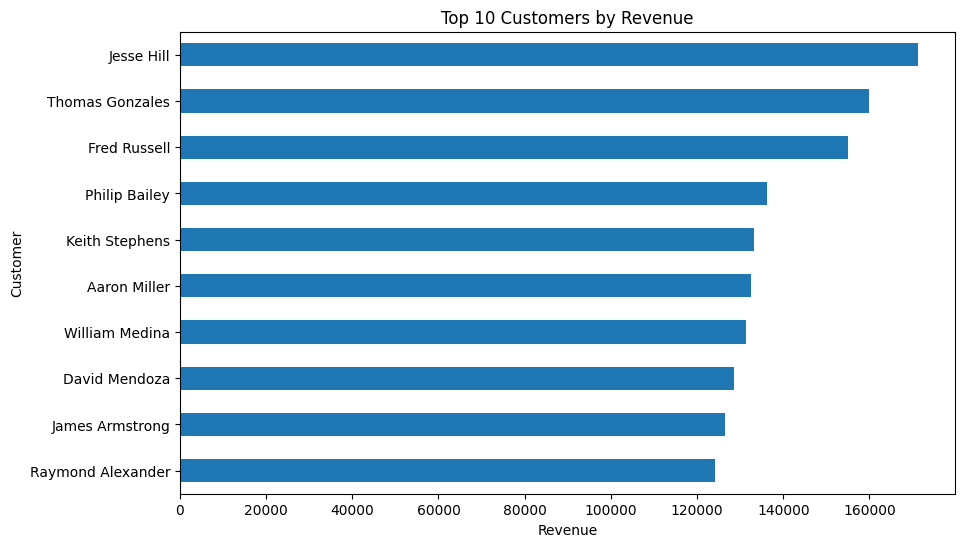

In [58]:
plt.figure(figsize=(10,6))                                     #top 10 customers chart

top_customers.sort_values().plot(kind="barh")

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Customer")

plt.show()

In [59]:
#no of orders by each customer
customer_orders = (
    sales_analysis
    .groupby("Customer Name")["Order ID"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

customer_orders

,Order ID
Customer Name,
Jesse Hill,66
Thomas Gonzales,64
Fred Russell,56
William Medina,55
Keith Stephens,55
Philip Bailey,55
James Armstrong,55
Aaron Miller,54
Frank Brown,51


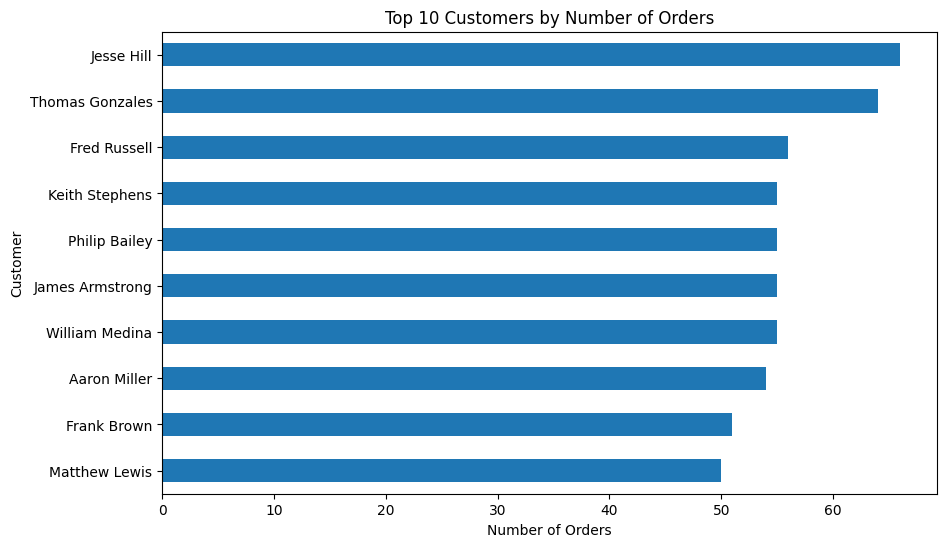

In [60]:
#chart
plt.figure(figsize=(10,6))

customer_orders.sort_values().plot(kind="barh")

plt.title("Top 10 Customers by Number of Orders")
plt.xlabel("Number of Orders")
plt.ylabel("Customer")

plt.show()

In [61]:
#Average Order Value

#Now we'll calculate:

#Average Order Value = Total Revenue / Number of Orders
total_orders=sales_analysis["Order ID"].nunique()
print(total_orders)

10889


In [62]:
average_order_value = (
    sales_analysis["revenue"].sum() / total_orders
)

print("Average Order Value:", average_order_value)

Average Order Value: 2356.617595738819


In [63]:
orders_per_customer=sales_analysis.groupby("Customer ID")["Order ID"].nunique()
print(orders_per_customer)

Customer ID
C1000    15
C1001    15
C1002    18
C1003    22
C1004    13
         ..
C1796    15
C1797    12
C1798    18
C1799    17
C1800    12
Name: Order ID, Length: 801, dtype: int64


In [64]:
repeat_customer=(orders_per_customer>1).sum()        #repeat customers
print(repeat_customer)

801


In [65]:
total_customers=orders_per_customer.shape[0]
print(total_customers)

801


In [66]:
repeat_customer_percentage=(repeat_customer/total_customers)*100
print("repeat customer percentage=",repeat_customer_percentage,"%")

repeat customer percentage= 100.0 %


In [67]:
customer_summary=(sales_analysis.groupby("Customer Name").agg(   #customer summary
    total_Revenue=("revenue","sum"),
    total_Orders=("Order ID","nunique"),
    total_Quantity=("Quantity","sum"),
    total_Profit=("profit","sum")
).reset_index())

In [68]:
customer_summary.head()

,Customer Name,total_Revenue,total_Orders,total_Quantity,total_Profit
0,Aaron Carr,75080,32,70,25620
1,Aaron Cruz,54110,20,38,18128
2,Aaron Day,55306,17,35,16799
3,Aaron Johnson,40228,18,32,13748
4,Aaron Miller,132550,54,104,41176


In [69]:
customer_summary.sort_values("total_Revenue",ascending=False).head(10)   #sort according to total_revenue

,Customer Name,total_Revenue,total_Orders,total_Quantity,total_Profit
234,Jesse Hill,171261,66,150,56204
467,Thomas Gonzales,159876,64,131,50675
171,Fred Russell,154998,56,119,52185
355,Philip Bailey,136175,55,124,40539
285,Keith Stephens,133183,55,110,39671
4,Aaron Miller,132550,54,104,41176
503,William Medina,131349,55,107,43508
125,David Mendoza,128460,44,91,43509
205,James Armstrong,126377,55,99,35442
378,Raymond Alexander,124217,47,88,40985


In [70]:
#locations related
locations.columns

Index(['Location ID', 'Name', 'County', 'State Code', 'State', 'Type',
       'Latitude', 'Longitude', 'Area Code', 'Population', 'Households',
       'Median Income', 'Land Area', 'Water Area', 'Time Zone'],
      dtype='object')

In [71]:
#location sales
location_sales=sales_analysis.groupby("Name")["revenue"].sum().sort_values(ascending=False).head(10)
print(location_sales)

Name
Rialto         465604
Roseville      436995
Victorville    423411
El Monte       419590
Escondido      412448
Fontana        410252
San Jose       399591
Oakland        398961
Modesto        396427
Concord        395430
Name: revenue, dtype: int64


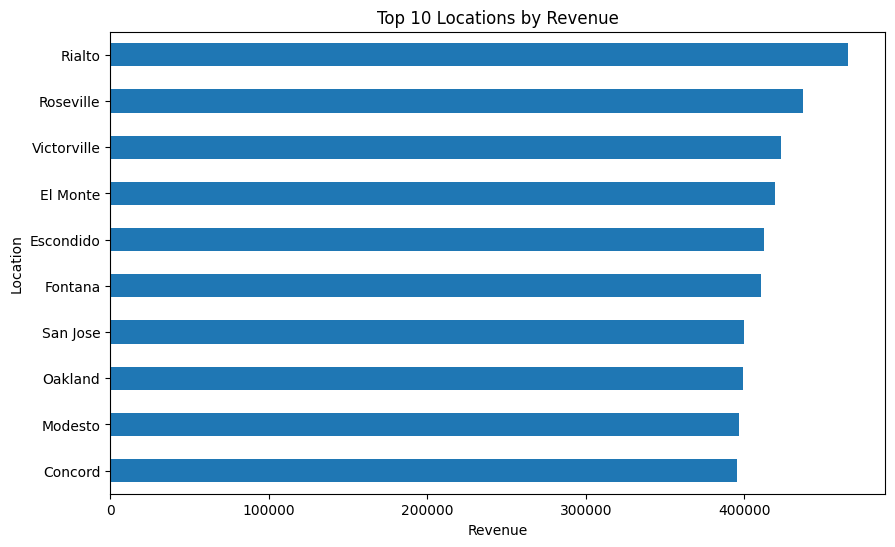

In [72]:
#plot
plt.figure(figsize=(10,6))

location_sales.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Locations by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Location")

plt.show()

In [73]:
#sales people analysis
sales_people.columns

Index(['Salesperson ID', 'Salesperson Name'], dtype='object')

In [74]:
#sales by salesperson
salesperson_revenue = (
    sales_analysis
    .groupby("Salesperson Name")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

salesperson_revenue.head(10)

,revenue
Salesperson Name,
Kenneth Bradley,678815
Ryan Welch,668305
Bobby Russell,653277
Brian Davis,638742
Patrick Ruiz,628457
Martin Perry,626396
Kenneth Fields,618409
Kevin Butler,604929
Scott Mason,604278


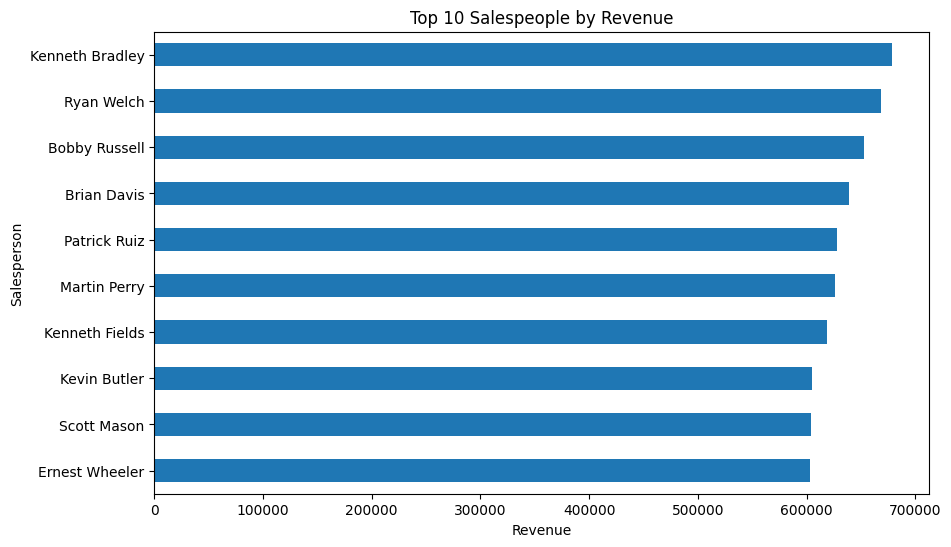

In [75]:
#chart
plt.figure(figsize=(10,6))

salesperson_revenue.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Salespeople by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Salesperson")

plt.show()

In [76]:
#sales summary
salesperson_summary = (
    sales_analysis
    .groupby("Salesperson Name")
    .agg(
        Total_Revenue=("revenue", "sum"),
        Total_Orders=("Order ID", "nunique"),
        Total_Quantity=("Quantity", "sum"),
        Total_Profit=("profit", "sum")
    )
    .reset_index()
)

In [77]:
salesperson_summary.sort_values(
    "Total_Revenue",
    ascending=False
).head(10)

,Salesperson Name,Total_Revenue,Total_Orders,Total_Quantity,Total_Profit
27,Kenneth Bradley,678815,262,552,227309
40,Ryan Welch,668305,273,529,221639
2,Bobby Russell,653277,252,515,214249
3,Brian Davis,638742,269,492,203946
34,Patrick Ruiz,628457,267,521,202312
33,Martin Perry,626396,245,492,204673
28,Kenneth Fields,618409,257,507,191995
29,Kevin Butler,604929,239,477,198505
42,Scott Mason,604278,238,471,203848
12,Ernest Wheeler,602977,263,493,199486


In [78]:
#profit analysis
#profit by product
product_profit = (
    sales_analysis
    .groupby("Product Name")["profit"]
    .sum()
    .sort_values(ascending=False)
)

product_profit.head(10)


,profit
Product Name,
Product 28,247808
Product 41,214288
Product 79,209231
Product 47,206052
Product 64,202554
Product 51,196900
Product 31,196650
Product 29,186966
Product 34,183634


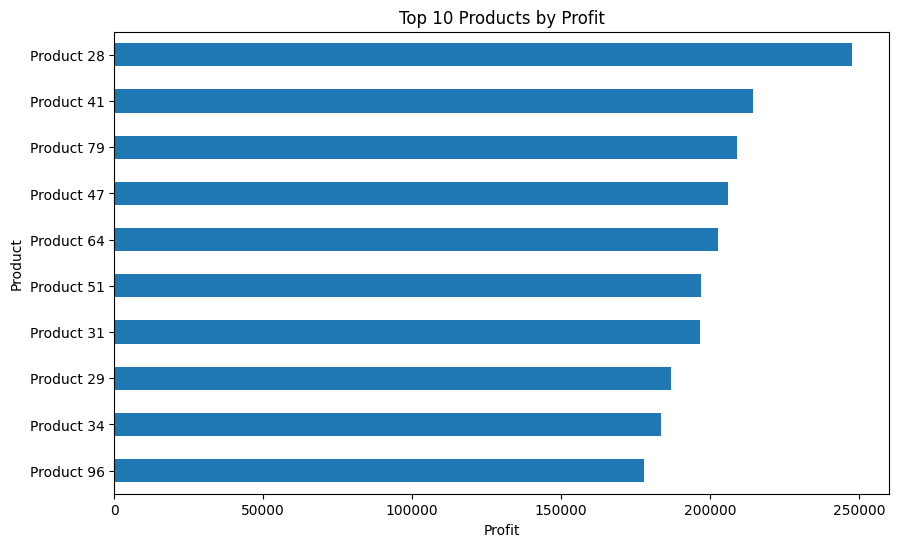

In [79]:
plt.figure(figsize=(10,6))

product_profit.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Products by Profit")
plt.xlabel("Profit")
plt.ylabel("Product")

plt.show()

In [80]:
#products with negative profit
loss_products = (
    sales_analysis
    .groupby("Product Name")["profit"]
    .sum()
    .sort_values()
)

loss_products.head(10)

,profit
Product Name,
Product 18,2899
Product 94,5280
Product 74,6664
Product 87,7215
Product 22,11178
Product 43,11417
Product 58,11475
Product 55,12288
Product 72,12864


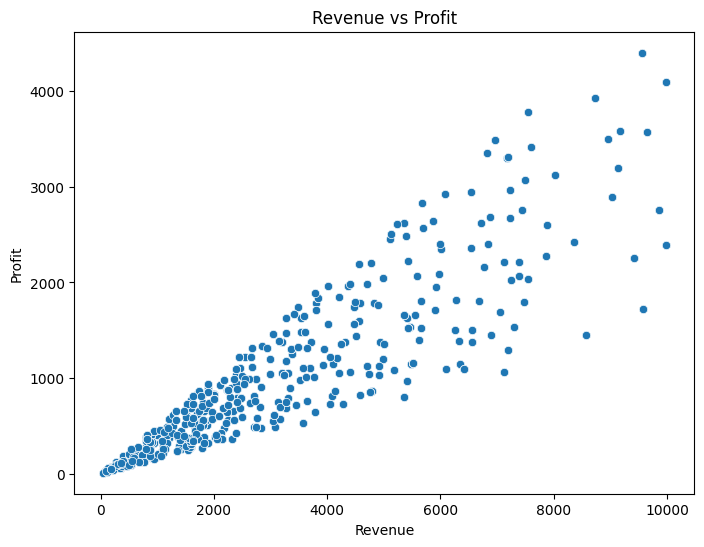

In [81]:
#revenue vs profit
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=sales_analysis,
    x="revenue",
    y="profit"
)

plt.title("Revenue vs Profit")
plt.xlabel("Revenue")
plt.ylabel("Profit")

plt.show()

In [82]:
#overall summarytotal_revenue = sales_analysis["Revenue"].sum()
total_profit = sales_analysis["profit"].sum()
total_orders = sales_analysis["Order ID"].nunique()
total_customers = sales_analysis["Customer ID"].nunique()
total_products = sales_analysis["Product ID"].nunique()
total_quantity = sales_analysis["Quantity"].sum()

print("===== E-COMMERCE SALES SUMMARY =====")
print("Total Revenue:", total_revenue)
print("Total Profit:", total_profit)
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Total Products:", total_products)
print("Total Quantity Sold:", total_quantity)

===== E-COMMERCE SALES SUMMARY =====
Total Revenue: 25661209
Total Profit: 8343893
Total Orders: 10889
Total Customers: 801
Total Products: 101
Total Quantity Sold: 21078


In [83]:
#correlation analysis
numeric_data = sales_analysis[
    ["Quantity", "Price", "revenue", "profit"]
]

In [84]:
correlation = numeric_data.corr()

correlation

,Quantity,Price,revenue,profit
Quantity,1.000000,0.000399,0.641259,0.573153
Price,0.000399,1.000000,0.669886,0.615641
revenue,0.641259,0.669886,1.000000,0.907773
profit,0.573153,0.615641,0.907773,1.000000


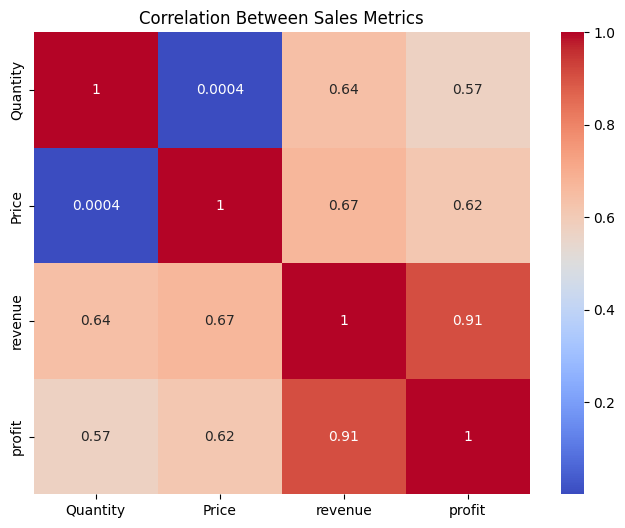

In [85]:
plt.figure(figsize=(8,6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Between Sales Metrics")

plt.show()

In [86]:
#final kpi table
kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Revenue",
        "Total Profit",
        "Total Orders",
        "Total Customers",
        "Total Products",
        "Total Quantity Sold"
    ],
    "Value": [
        sales_analysis["revenue"].sum(),
        sales_analysis["profit"].sum(),
        sales_analysis["Order ID"].nunique(),
        sales_analysis["Customer ID"].nunique(),
        sales_analysis["Product ID"].nunique(),
        sales_analysis["Quantity"].sum()
    ]
})

kpi_summary

,Metric,Value
0,Total Revenue,25661209
1,Total Profit,8343893
2,Total Orders,10889
3,Total Customers,801
4,Total Products,101
5,Total Quantity Sold,21078


In [87]:
#monthly revenue
monthly_revenue = (
    sales_analysis
    .groupby(
        sales_analysis["Purchase Date"].dt.to_period("M")
    )["revenue"]
    .sum()
    .reset_index()
)

monthly_revenue["Purchase Date"] = (
    monthly_revenue["Purchase Date"].dt.to_timestamp()
)

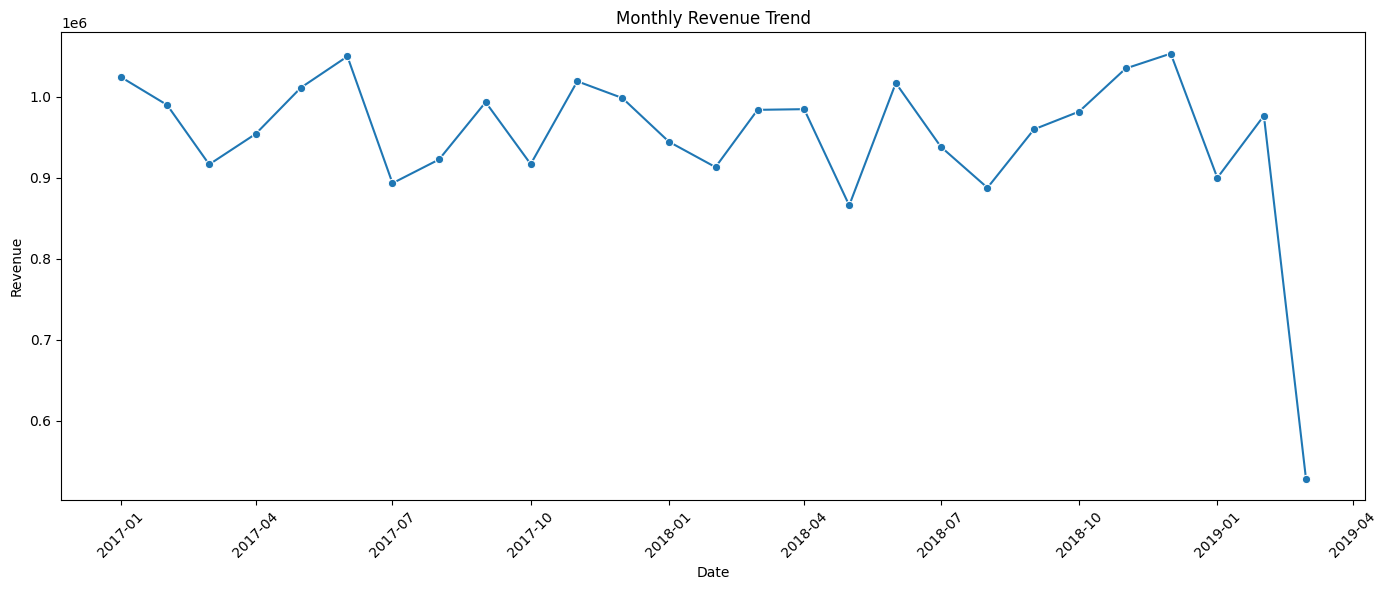

In [88]:
#plot
plt.figure(figsize=(14,6))

sns.lineplot(
    data=monthly_revenue,
    x="Purchase Date",
    y="revenue",
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [89]:
#top 10 products
top_products = (
    sales_analysis
    .groupby("Product Name")
    .agg(
        Total_Revenue=("revenue", "sum"),
        Total_Quantity=("Quantity", "sum"),
        Total_Profit=("profit", "sum")
    )
    .sort_values(
        "Total_Revenue",
        ascending=False
    )
    .head(10)
    .reset_index()
)

top_products

,Product Name,Total_Revenue,Total_Quantity,Total_Profit
0,Product 63,628320,255,175950
1,Product 28,604274,242,247808
2,Product 47,556710,231,206052
3,Product 29,534222,234,186966
4,Product 84,528827,247,89908
5,Product 59,523624,232,167504
6,Product 56,484030,194,116206
7,Product 66,474408,198,85338
8,Product 33,468146,238,135660
9,Product 81,465894,198,111870


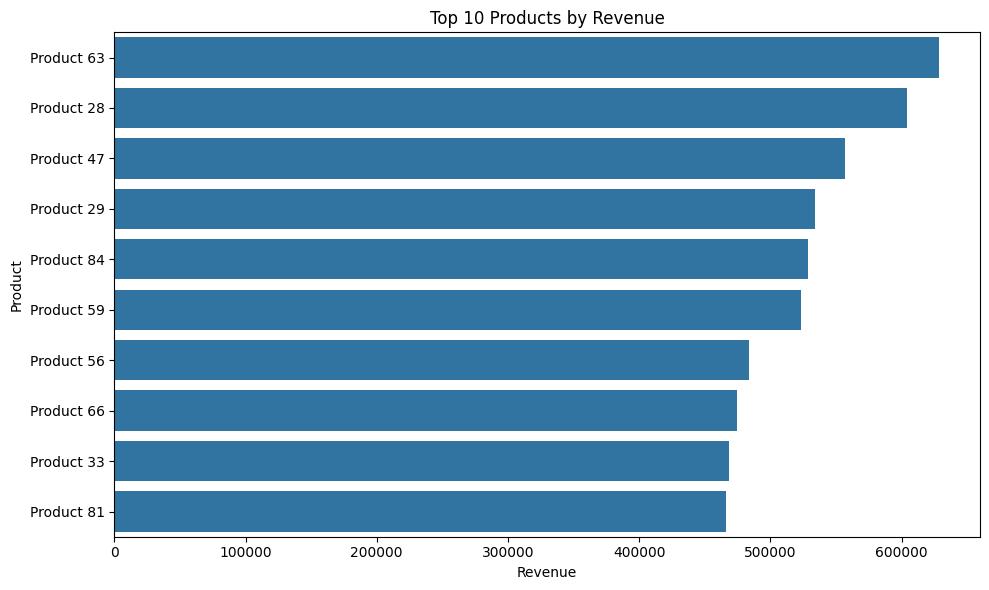

In [90]:
#viswalize revenue
plt.figure(figsize=(10,6))

sns.barplot(
    data=top_products,
    y="Product Name",
    x="Total_Revenue"
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

In [91]:
#top 10 customers
top_customers = (
    sales_analysis
    .groupby("Customer Name")
    .agg(
        Total_Revenue=("revenue", "sum"),
        Total_Orders=("Order ID", "nunique"),
        Total_Profit=("profit", "sum")
    )
    .sort_values(
        "Total_Revenue",
        ascending=False
    )
    .head(10)
    .reset_index()
)

top_customers

,Customer Name,Total_Revenue,Total_Orders,Total_Profit
0,Jesse Hill,171261,66,56204
1,Thomas Gonzales,159876,64,50675
2,Fred Russell,154998,56,52185
3,Philip Bailey,136175,55,40539
4,Keith Stephens,133183,55,39671
5,Aaron Miller,132550,54,41176
6,William Medina,131349,55,43508
7,David Mendoza,128460,44,43509
8,James Armstrong,126377,55,35442
9,Raymond Alexander,124217,47,40985


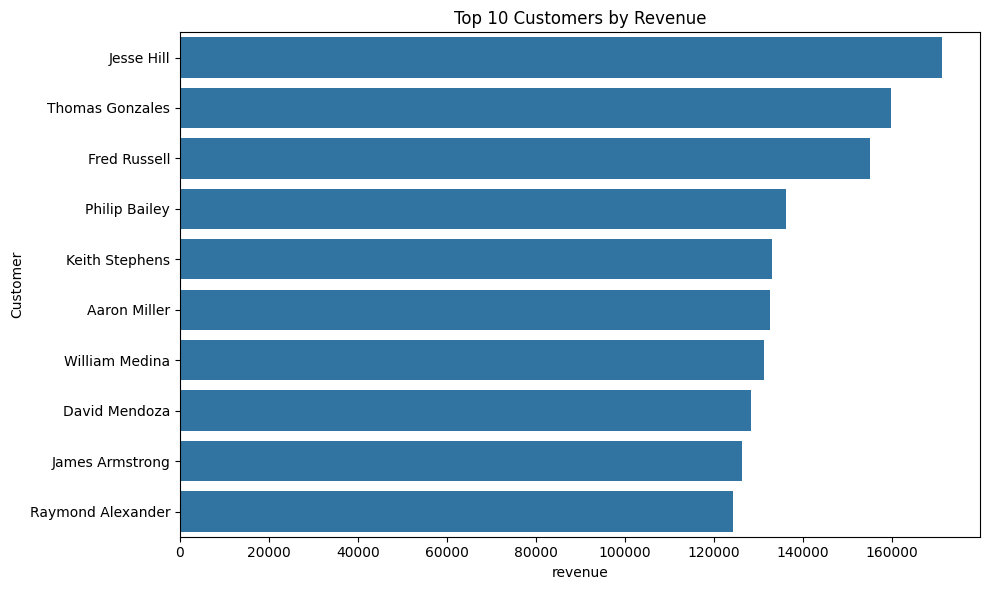

In [92]:
#chart
plt.figure(figsize=(10,6))

sns.barplot(
    data=top_customers,
    y="Customer Name",
    x="Total_Revenue"
)

plt.title("Top 10 Customers by Revenue")
plt.xlabel("revenue")
plt.ylabel("Customer")

plt.tight_layout()
plt.show()

In [93]:
#top locations
top_locations = (
    sales_analysis
    .groupby("Name")
    .agg(
        Total_Revenue=("revenue", "sum"),
        Total_Orders=("Order ID", "nunique"),
        Total_Profit=("profit", "sum")
    )
    .sort_values(
        "Total_Revenue",
        ascending=False
    )
    .head(10)
    .reset_index()
)

top_locations

,Name,Total_Revenue,Total_Orders,Total_Profit
0,Rialto,465604,168,157897
1,Roseville,436995,173,146143
2,Victorville,423411,163,133708
3,El Monte,419590,179,132431
4,Escondido,412448,172,133955
5,Fontana,410252,160,131769
6,San Jose,399591,156,138035
7,Oakland,398961,144,128024
8,Modesto,396427,160,118084
9,Concord,395430,153,132109


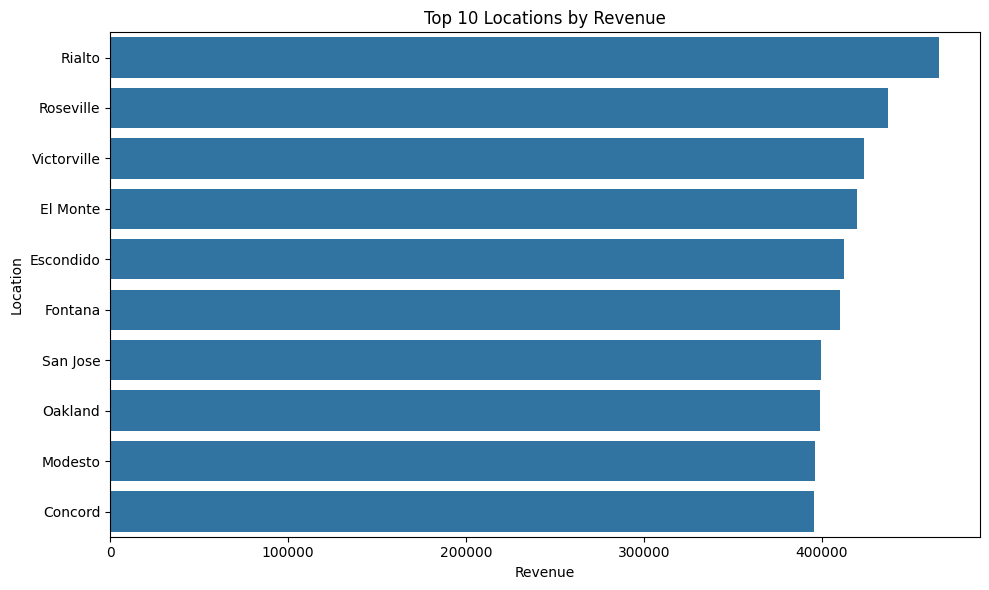

In [94]:
#fig
plt.figure(figsize=(10,6))

sns.barplot(
    data=top_locations,
    y="Name",
    x="Total_Revenue"
)

plt.title("Top 10 Locations by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Location")

plt.tight_layout()
plt.show()

In [95]:
#best selling product
best_product = (
    sales_analysis
    .groupby("Product Name")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(1)
)

best_product

,Quantity
Product Name,
Product 24,289


In [96]:
#highest revenue product
highest_revenue_product = (
    sales_analysis
    .groupby("Product Name")["revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(1)
)

highest_revenue_product

,revenue
Product Name,
Product 63,628320


In [97]:
#most proffitable product
most_profitable_product = (
    sales_analysis
    .groupby("Product Name")["profit"]
    .sum()
    .sort_values(ascending=False)
    .head(1)
)

most_profitable_product

,profit
Product Name,
Product 28,247808


## Key Business Insights

1. Analyzed total revenue, profit and order performance across multiple years.

2. Identified the top-performing products based on revenue and quantity sold.

3. Identified high-value customers based on total revenue and number of orders.

4. Analyzed monthly revenue trends to identify changes in sales performance.

5. Compared revenue and profit across different locations.

6. Evaluated salesperson performance using revenue, orders and profit.

7. Investigated relationships between quantity, price, revenue and profit.

# Executive Summary

In [99]:
print("Total Revenue:", sales_analysis["Revenue"].sum())
print("Total Profit:", sales_analysis["Profit"].sum())
print("Total Orders:", sales_analysis["Order ID"].nunique())
print("Total Customers:", sales_analysis["Customer ID"].nunique())
print("Total Products:", sales_analysis["Product ID"].nunique())

Total Revenue: 25661209
Total Profit: 8343893
Total Orders: 10889
Total Customers: 801
Total Products: 101


# Conclusion

The analysis provides an overview of e-commerce sales performance across
products, customers, locations and salespeople.

The project used Python to clean, transform, merge and analyze multiple
data sources and generate visual insights.

The analysis helps identify high-performing products and customers,
revenue trends, location-wise performance and profitability patterns.